### 1. Load the Dataset and Initial Exploration

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '/content/MoveInSync_500_Low_Rating_Reviews.csv'
df = pd.read_csv(file_path)

# Display basic information
print("=== Dataset Shape ===")
print(df.shape)
print("\n=== Column Information ===")
df.info()
print("\n=== First 5 Rows ===")
display(df.head())

=== Dataset Shape ===
(500, 19)

=== Column Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   review_id                    500 non-null    object
 1   star_rating                  500 non-null    int64 
 2   review_date_utc              500 non-null    object
 3   app_version                  449 non-null    object
 4   thumbs_up_count              500 non-null    int64 
 5   primary_theme                500 non-null    object
 6   theme_tags                   500 non-null    object
 7   review_text_char_count       500 non-null    int64 
 8   developer_replied            500 non-null    bool  
 9   developer_reply_date_utc     239 non-null    object
 10  source_listing_url           500 non-null    object
 11  review_url                   500 non-null    object
 12  country                      500

,review_id,star_rating,review_date_utc,app_version,thumbs_up_count,primary_theme,theme_tags,review_text_char_count,developer_replied,developer_reply_date_utc,source_listing_url,review_url,country,language_request,collection_timestamp_utc,sampling_seed,sampling_frame_size,eligible_low_star_pool_size,sampling_method
0,afb20a84-886d-43d1-bfa0-02812763db66,1,2019-11-24T00:52:53+00:00,6.8.7,0,Other / unclear,Other / unclear,40,True,2019-11-25T12:58:39+00:00,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11T05:58:00.183039+00:00,42,15000,4619,Simple random sample without replacement from ...
1,f305241a-07af-4a27-a636-34fe76e47755,1,2019-11-26T02:05:24+00:00,6.8.7,0,GPS / ETA / live tracking,GPS / ETA / live tracking,30,False,NaN,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11T05:58:00.183039+00:00,42,15000,4619,Simple random sample without replacement from ...
2,39d4f843-fddf-4f11-a2b8-459fb6370e02,2,2019-11-26T04:33:49+00:00,NaN,0,Booking / scheduling,Booking / scheduling|GPS / ETA / live tracking...,233,False,NaN,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11T05:58:00.183039+00:00,42,15000,4619,Simple random sample without replacement from ...
3,94b3f367-bf79-4292-aff6-d75b6fa4665f,1,2019-11-26T14:50:33+00:00,7.0.3,0,Other / unclear,Other / unclear,14,True,2019-11-29T05:26:23+00:00,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11T05:58:00.183039+00:00,42,15000,4619,Simple random sample without replacement from ...
4,02711ca0-1301-4f21-9ca7-83dded144a4e,2,2019-11-27T10:12:12+00:00,6.8.2,0,Crash / performance,Crash / performance|Driver / vehicle operations,113,False,NaN,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11T05:58:00.183039+00:00,42,15000,4619,Simple random sample without replacement from ...


### 2. Deep Dive Exploration (Null Values & Statistics)

In [ ]:
# Checking missing values
missing_values = df.isnull().sum()
print("=== Missing Values Per Column ===")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found!")

# Numerical Columns Description
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if numerical_cols:
    print("\n=== Numerical Summary ===")
    display(df[numerical_cols].describe())

# Categorical/Text Columns Description
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
if categorical_cols:
    print("\n=== Categorical/Text Summary ===")
    display(df[categorical_cols].describe(include='all'))

=== Missing Values Per Column ===
app_version                  51
developer_reply_date_utc    261
dtype: int64

=== Numerical Summary ===


,star_rating,thumbs_up_count,review_text_char_count,sampling_seed,sampling_frame_size,eligible_low_star_pool_size
count,500.000000,500.000000,500.000000,500.0,500.0,500.0
mean,1.102000,0.634000,104.060000,42.0,15000.0,4619.0
std,0.302951,4.489583,103.939459,0.0,0.0,0.0
min,1.000000,0.000000,3.000000,42.0,15000.0,4619.0
25%,1.000000,0.000000,28.000000,42.0,15000.0,4619.0
50%,1.000000,0.000000,68.500000,42.0,15000.0,4619.0
75%,1.000000,0.000000,146.250000,42.0,15000.0,4619.0
max,2.000000,67.000000,497.000000,42.0,15000.0,4619.0



=== Categorical/Text Summary ===


,review_id,review_date_utc,app_version,primary_theme,theme_tags,developer_reply_date_utc,source_listing_url,review_url,country,language_request,collection_timestamp_utc,sampling_method
count,500,500,449,500,500,239,500,500,500,500,500,500
unique,500,500,115,9,71,239,1,500,1,1,1,1
top,7476b129-f0da-458e-8f86-d77ba2f9a710,2026-10-09T02:52:55+00:00,11.4.13,Other / unclear,Other / unclear,2019-11-25T12:58:39+00:00,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11T05:58:00.183039+00:00,Simple random sample without replacement from ...
freq,1,1,28,163,163,1,500,1,500,500,500,500


### 3. Data Preprocessing
We will dynamically clean missing values, handle categorical columns, and clean text strings if there are any reviews or comments text fields.

In [ ]:
# Copy dataframe for preprocessing
df_clean = df.copy()

# Standardize text columns (strip whitespace, convert to lowercase if appropriate)
for col in df_clean.select_dtypes(include=['object']).columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# Depending on the dataset columns, we'll replace missing values in object columns with 'Unknown'
for col in df_clean.select_dtypes(include=['object']).columns:
    df_clean[col] = df_clean[col].fillna('Unknown')

# Check for date-like columns to convert to datetime format
for col in df_clean.columns:
    if 'date' in col.lower() or 'time' in col.lower():
        try:
            df_clean[col] = pd.to_datetime(df_clean[col], errors='coerce')
            print(f"Converted {col} to datetime format.")
        except Exception:
            pass

print("\n=== Preprocessed Dataset Sample ===")
display(df_clean.head())

Converted review_date_utc to datetime format.
Converted developer_reply_date_utc to datetime format.
Converted collection_timestamp_utc to datetime format.

=== Preprocessed Dataset Sample ===


,review_id,star_rating,review_date_utc,app_version,thumbs_up_count,primary_theme,theme_tags,review_text_char_count,developer_replied,developer_reply_date_utc,source_listing_url,review_url,country,language_request,collection_timestamp_utc,sampling_seed,sampling_frame_size,eligible_low_star_pool_size,sampling_method
0,afb20a84-886d-43d1-bfa0-02812763db66,1,2019-11-24 00:52:53+00:00,6.8.7,0,Other / unclear,Other / unclear,40,True,2019-11-25 12:58:39+00:00,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11 05:58:00.183039+00:00,42,15000,4619,Simple random sample without replacement from ...
1,f305241a-07af-4a27-a636-34fe76e47755,1,2019-11-26 02:05:24+00:00,6.8.7,0,GPS / ETA / live tracking,GPS / ETA / live tracking,30,False,NaT,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11 05:58:00.183039+00:00,42,15000,4619,Simple random sample without replacement from ...
2,39d4f843-fddf-4f11-a2b8-459fb6370e02,2,2019-11-26 04:33:49+00:00,nan,0,Booking / scheduling,Booking / scheduling|GPS / ETA / live tracking...,233,False,NaT,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11 05:58:00.183039+00:00,42,15000,4619,Simple random sample without replacement from ...
3,94b3f367-bf79-4292-aff6-d75b6fa4665f,1,2019-11-26 14:50:33+00:00,7.0.3,0,Other / unclear,Other / unclear,14,True,2019-11-29 05:26:23+00:00,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11 05:58:00.183039+00:00,42,15000,4619,Simple random sample without replacement from ...
4,02711ca0-1301-4f21-9ca7-83dded144a4e,2,2019-11-27 10:12:12+00:00,6.8.2,0,Crash / performance,Crash / performance|Driver / vehicle operations,113,False,NaT,https://play.google.com/store/apps/details?id=...,https://play.google.com/store/apps/details?id=...,in,en,2026-10-11 05:58:00.183039+00:00,42,15000,4619,Simple random sample without replacement from ...


### 4. Visual Exploratory Data Analysis (EDA)

/tmp/ipykernel_3216/3836093587.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0], data=df_clean, x='star_rating', palette='viridis')


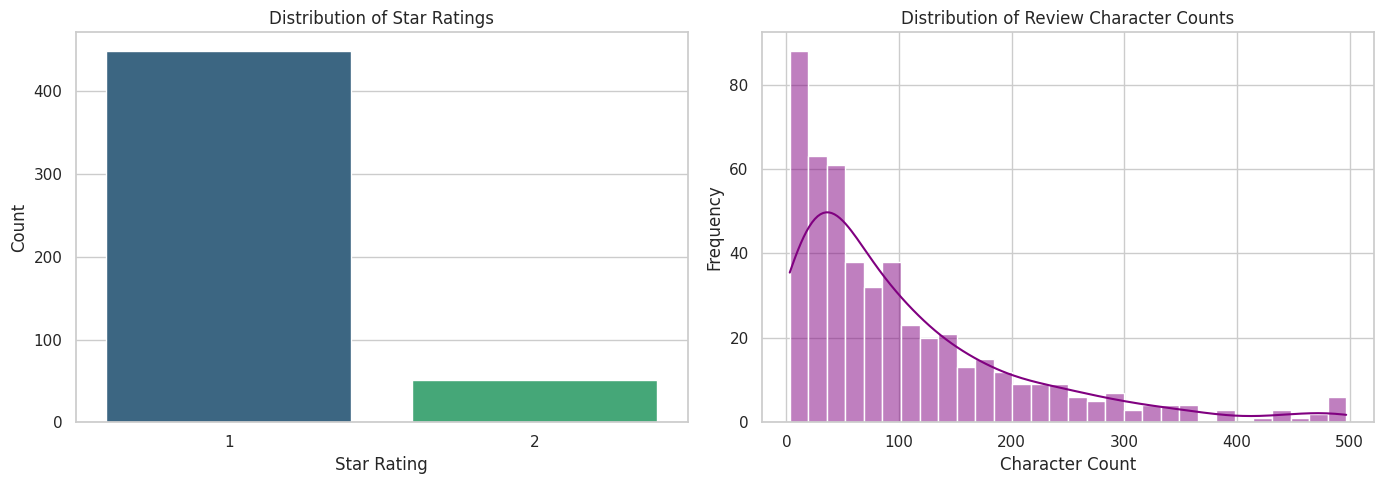

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetic styles for the plots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribution of Star Ratings
sns.countplot(ax=axes[0], data=df_clean, x='star_rating', palette='viridis')
axes[0].set_title('Distribution of Star Ratings')
axes[0].set_xlabel('Star Rating')
axes[0].set_ylabel('Count')

# 2. Distribution of Review Character Lengths
sns.histplot(ax=axes[1], data=df_clean, x='review_text_char_count', kde=True, color='purple', bins=30)
axes[1].set_title('Distribution of Review Character Counts')
axes[1].set_xlabel('Character Count')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

/tmp/ipykernel_3216/3678817471.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=theme_counts.values, y=theme_counts.index, palette='magma')


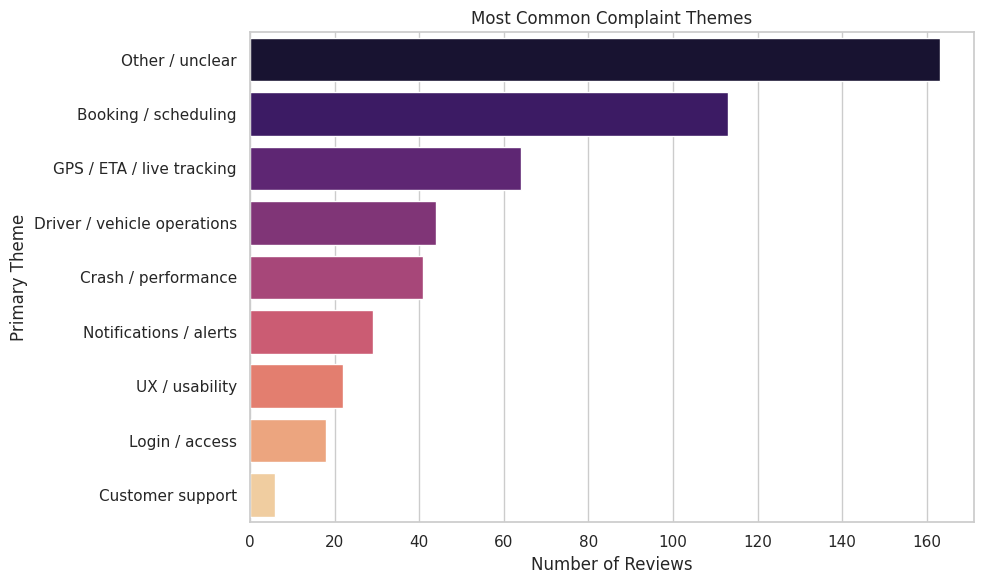

In [ ]:
plt.figure(figsize=(10, 6))

# 3. Frequency of Primary Complaint Themes
theme_counts = df_clean['primary_theme'].value_counts()
sns.barplot(x=theme_counts.values, y=theme_counts.index, palette='magma')
plt.title('Most Common Complaint Themes')
plt.xlabel('Number of Reviews')
plt.ylabel('Primary Theme')
plt.tight_layout()
plt.show()

/tmp/ipykernel_3216/3904907268.py:5: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_clean['review_month'] = df_clean['review_date_utc'].dt.to_period('M')


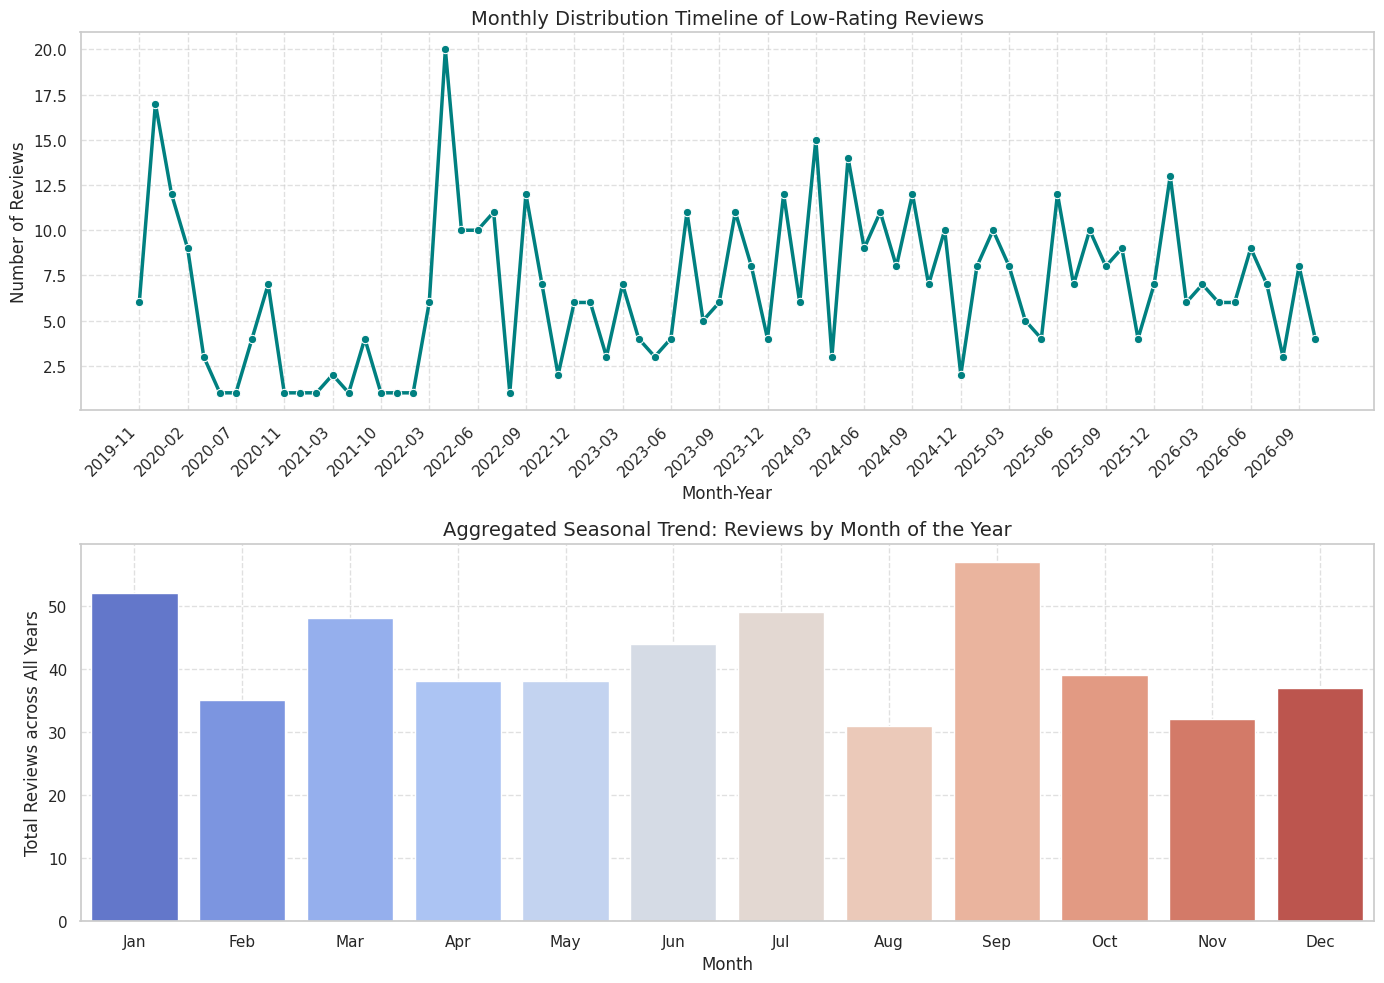

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Reviews over Time (Improved Monthly Trend)
df_clean['review_month'] = df_clean['review_date_utc'].dt.to_period('M')
monthly_reviews = df_clean.groupby('review_month').size().reset_index(name='count')
monthly_reviews['review_month'] = monthly_reviews['review_month'].astype(str)

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Subplot 1: Monthly Timeline of Reviews
sns.lineplot(ax=axes[0], data=monthly_reviews, x='review_month', y='count', marker='o', linewidth=2.5, color='teal')
axes[0].set_title('Monthly Distribution Timeline of Low-Rating Reviews', fontsize=14)
axes[0].set_xlabel('Month-Year', fontsize=12)
axes[0].set_ylabel('Number of Reviews', fontsize=12)
# Show fewer ticks on the timeline to prevent overcrowding
ticks_to_show = monthly_reviews['review_month'][::3]
axes[0].set_xticks(ticks_to_show)
axes[0].set_xticklabels(ticks_to_show, rotation=45, ha='right')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Seasonal / Month-of-Year Distribution (Aggregated Seasonality)
df_clean['month_num'] = df_clean['review_date_utc'].dt.month
seasonal_reviews = df_clean.groupby('month_num').size().reset_index(name='count')
month_names = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
seasonal_reviews['month_name'] = seasonal_reviews['month_num'].map(month_names)

sns.barplot(ax=axes[1], data=seasonal_reviews, x='month_name', y='count', palette='coolwarm', hue='month_name', legend=False)
axes[1].set_title('Aggregated Seasonal Trend: Reviews by Month of the Year', fontsize=14)
axes[1].set_xlabel('Month', fontsize=12)
axes[1].set_ylabel('Total Reviews across All Years', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 5. Save Generated Plots to Workspace

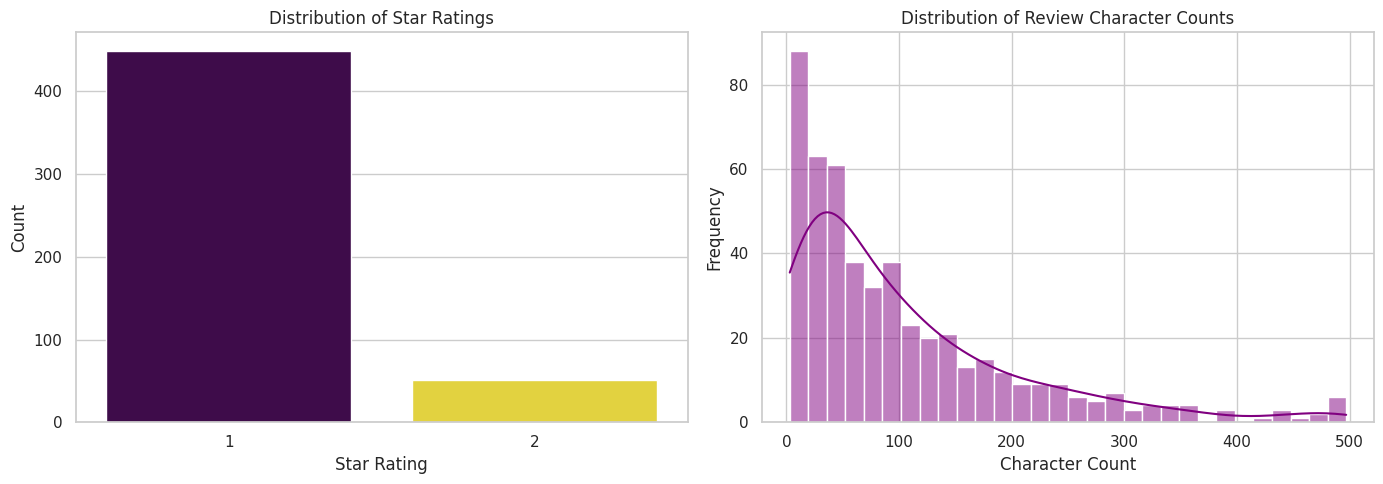

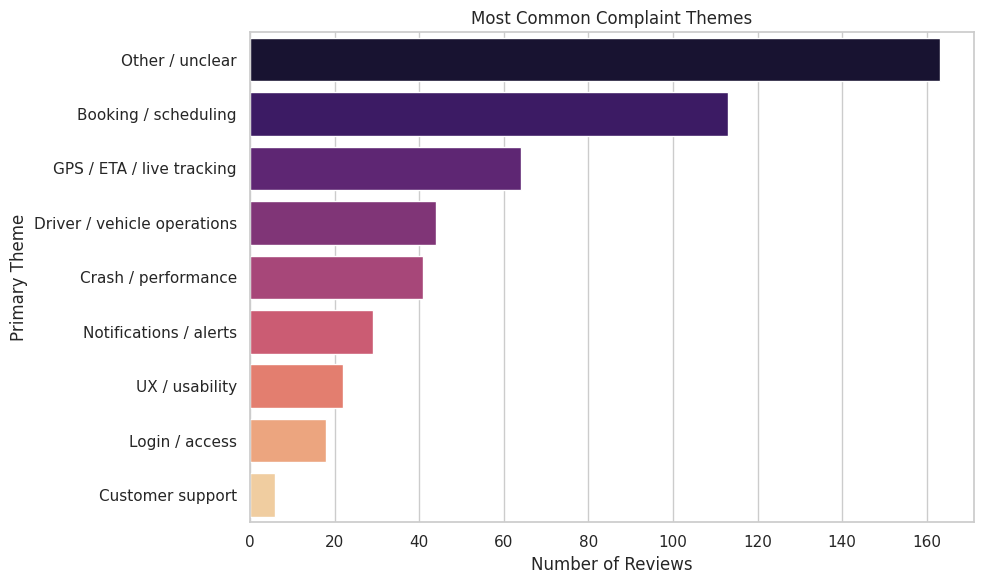

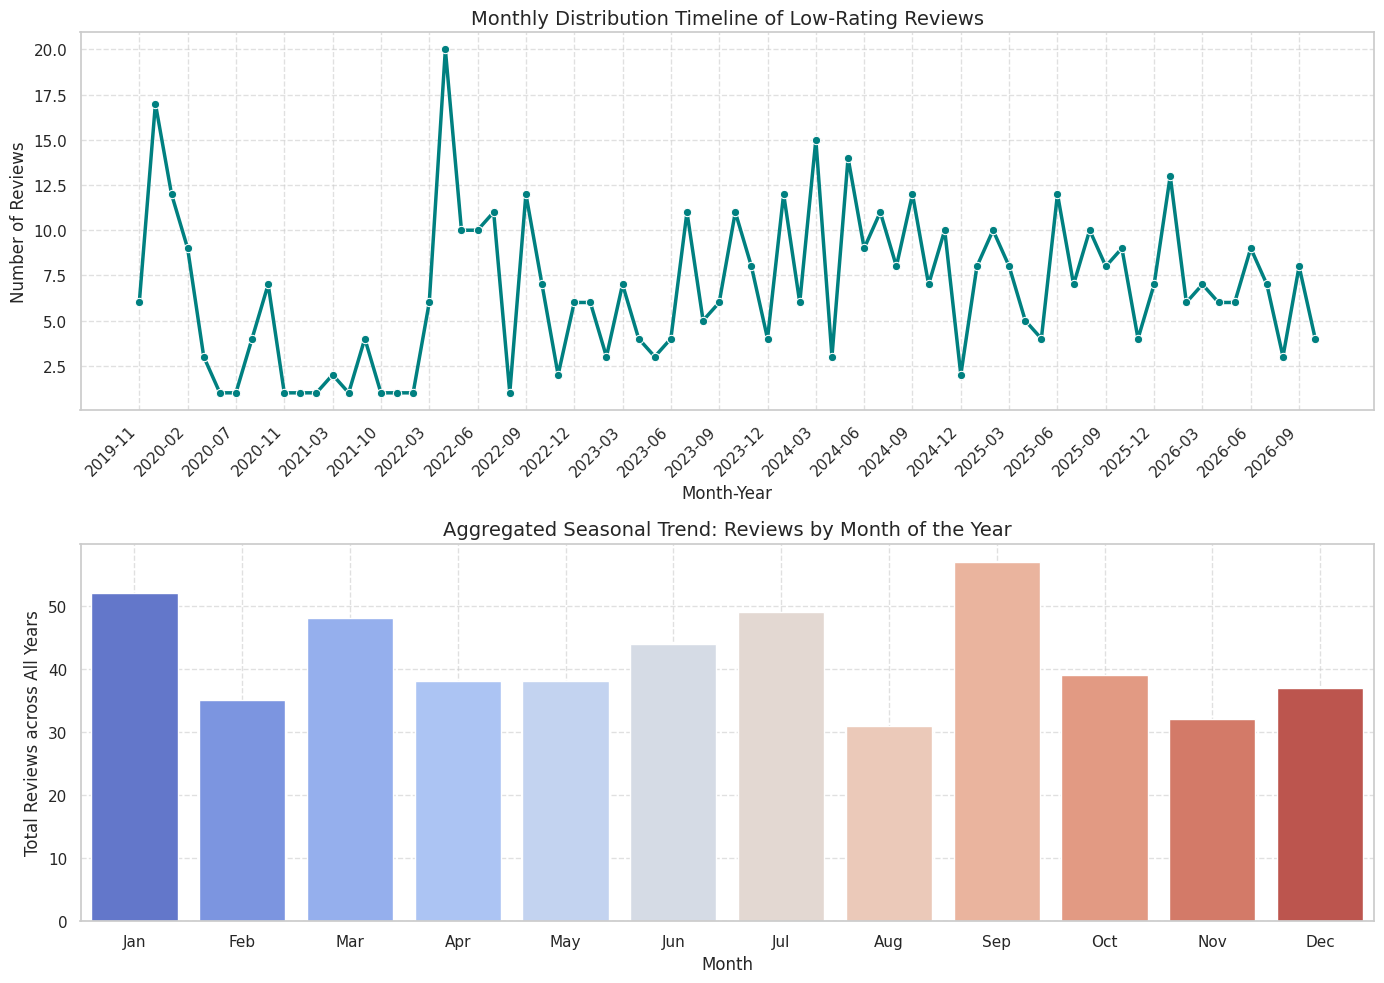

All figures successfully saved as PNGs in your workspace directory (/content/):
- ratings_and_character_counts.png
- common_complaint_themes.png
- monthly_and_seasonal_trends.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Re-generate and save the Ratings & Characters Distribution Plot
sns.set_theme(style="whitegrid")
fig1, axes1 = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(ax=axes1[0], data=df_clean, x='star_rating', hue='star_rating', palette='viridis', legend=False)
axes1[0].set_title('Distribution of Star Ratings')
axes1[0].set_xlabel('Star Rating')
axes1[0].set_ylabel('Count')

sns.histplot(ax=axes1[1], data=df_clean, x='review_text_char_count', kde=True, color='purple', bins=30)
axes1[1].set_title('Distribution of Review Character Counts')
axes1[1].set_xlabel('Character Count')
axes1[1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('/content/ratings_and_character_counts.png', dpi=300)
plt.show()

# 2. Re-generate and save the Primary Themes Complaint Plot
plt.figure(figsize=(10, 6))
theme_counts = df_clean['primary_theme'].value_counts()
sns.barplot(x=theme_counts.values, y=theme_counts.index, hue=theme_counts.index, palette='magma', legend=False)
plt.title('Most Common Complaint Themes')
plt.xlabel('Number of Reviews')
plt.ylabel('Primary Theme')
plt.tight_layout()
plt.savefig('/content/common_complaint_themes.png', dpi=300)
plt.show()

# 3. Re-generate and save the Timeline and Seasonal Trend Plots
fig2, axes2 = plt.subplots(2, 1, figsize=(14, 10))

sns.lineplot(ax=axes2[0], data=monthly_reviews, x='review_month', y='count', marker='o', linewidth=2.5, color='teal')
axes2[0].set_title('Monthly Distribution Timeline of Low-Rating Reviews', fontsize=14)
axes2[0].set_xlabel('Month-Year', fontsize=12)
axes2[0].set_ylabel('Number of Reviews', fontsize=12)
ticks_to_show = monthly_reviews['review_month'][::3]
axes2[0].set_xticks(ticks_to_show)
axes2[0].set_xticklabels(ticks_to_show, rotation=45, ha='right')
axes2[0].grid(True, linestyle='--', alpha=0.6)

sns.barplot(ax=axes2[1], data=seasonal_reviews, x='month_name', y='count', palette='coolwarm', hue='month_name', legend=False)
axes2[1].set_title('Aggregated Seasonal Trend: Reviews by Month of the Year', fontsize=14)
axes2[1].set_xlabel('Month', fontsize=12)
axes2[1].set_ylabel('Total Reviews across All Years', fontsize=12)
axes2[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('/content/monthly_and_seasonal_trends.png', dpi=300)
plt.show()

print("All figures successfully saved as PNGs in your workspace directory (/content/):")
print("- ratings_and_character_counts.png")
print("- common_complaint_themes.png")
print("- monthly_and_seasonal_trends.png")